In [1]:
!pip install anthropic --quiet

import os
import json
import anthropic
import numpy as np
import pandas as pd
from datetime import datetime
from dotenv import load_dotenv
from supabase import create_client, Client
from sklearn.ensemble import IsolationForest, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

load_dotenv(dotenv_path="/Users/mohamedmunir/Desktop/FinScope-Ai/ai-service/notebooks/.env", override=True)

supabase: Client = create_client(os.getenv("SUPABASE_URL"), os.getenv("SUPABASE_SERVICE_KEY"))
claude           = anthropic.Anthropic(api_key=os.getenv("ANTHROPIC_API_KEY"))

print("Connected to Supabase and Claude")


Connected to Supabase and Claude


In [2]:
# Tools the agent can call
TOOLS = [
    {
        "name": "pull_data",
        "description": "Pull all transactions and user finances from Supabase",
        "input_schema": {"type": "object", "properties": {}, "required": []}
    },
    {
        "name": "clean_data",
        "description": "Clean and prepare transaction data for ML models",
        "input_schema": {
            "type": "object",
            "properties": {
                "filter_type": {
                    "type": "string",
                    "description": "Filter by transaction type: expense, deposit, all",
                    "enum": ["expense", "deposit", "all"]
                }
            },
            "required": ["filter_type"]
        }
    },
    {
        "name": "run_anomaly_detection",
        "description": "Run Isolation Forest to detect anomalous transactions",
        "input_schema": {
            "type": "object",
            "properties": {
                "contamination": {
                    "type": "number",
                    "description": "Expected proportion of anomalies (0.05 to 0.3)"
                }
            },
            "required": ["contamination"]
        }
    },
    {
        "name": "run_clustering",
        "description": "Run KMeans to segment users into spending personas",
        "input_schema": {
            "type": "object",
            "properties": {
                "n_clusters": {
                    "type": "integer",
                    "description": "Number of user clusters (2 to 5)"
                }
            },
            "required": ["n_clusters"]
        }
    },
    {
        "name": "run_forecast",
        "description": "Run Gradient Boosting to forecast next 7 days of spending",
        "input_schema": {"type": "object", "properties": {}, "required": []}
    },
    {
        "name": "write_insights_to_supabase",
        "description": "Write all ML insights and recommendations back to Supabase",
        "input_schema": {
            "type": "object",
            "properties": {
                "insights": {
                    "type": "object",
                    "description": "Dict of insights to store"
                }
            },
            "required": ["insights"]
        }
    },
    {
        "name": "generate_report",
        "description": "Generate a final natural language report summarising all findings",
        "input_schema": {
            "type": "object",
            "properties": {
                "findings": {
                    "type": "object",
                    "description": "All ML findings to summarise"
                }
            },
            "required": ["findings"]
        }
    }
]

print(f"Defined {len(TOOLS)} agent tools")

# git commit -m "# Tools the agent can call
TOOLS = [
    {
        "name": "pull_data",
        "description": "Pull all transactions and user finances from Supabase",
        "input_schema": {"type": "object", "properties": {}, "required": []}
    },
    {
        "name": "clean_data",
        "description": "Clean and prepare transaction data for ML models",
        "input_schema": {
            "type": "object",
            "properties": {
                "filter_type": {
                    "type": "string",
                    "description": "Filter by transaction type: expense, deposit, all",
                    "enum": ["expense", "deposit", "all"]
                }
            },
            "required": ["filter_type"]
        }
    },
    {
        "name": "run_anomaly_detection",
        "description": "Run Isolation Forest to detect anomalous transactions",
        "input_schema": {
            "type": "object",
            "properties": {
                "contamination": {
                    "type": "number",
                    "description": "Expected proportion of anomalies (0.05 to 0.3)"
                }
            },
            "required": ["contamination"]
        }
    },
    {
        "name": "run_clustering",
        "description": "Run KMeans to segment users into spending personas",
        "input_schema": {
            "type": "object",
            "properties": {
                "n_clusters": {
                    "type": "integer",
                    "description": "Number of user clusters (2 to 5)"
                }
            },
            "required": ["n_clusters"]
        }
    },
    {
        "name": "run_forecast",
        "description": "Run Gradient Boosting to forecast next 7 days of spending",
        "input_schema": {"type": "object", "properties": {}, "required": []}
    },
    {
        "name": "write_insights_to_supabase",
        "description": "Write all ML insights and recommendations back to Supabase",
        "input_schema": {
            "type": "object",
            "properties": {
                "insights": {
                    "type": "object",
                    "description": "Dict of insights to store"
                }
            },
            "required": ["insights"]
        }
    },
    {
        "name": "generate_report",
        "description": "Generate a final natural language report summarising all findings",
        "input_schema": {
            "type": "object",
            "properties": {
                "findings": {
                    "type": "object",
                    "description": "All ML findings to summarise"
                }
            },
            "required": ["findings"]
        }
    }
]

print(f"Defined {len(TOOLS)} agent tools")



Defined 7 agent tools


In [8]:
def run_pipeline_agent():
    print("\n" + "=" * 60)
    print("  FINSCOPE AI — DATA PIPELINE AGENT")
    print("  Powered by Claude + Scikit-learn + Supabase")
    print("=" * 60)

    messages = [{
        "role": "user",
        "content": """You are an autonomous data pipeline agent for FinScope AI.

Your job is to run the full ML pipeline in this exact order:
1. Pull all data from Supabase
2. Clean the expense transactions
3. Run anomaly detection with appropriate contamination
4. Run user clustering with the right number of clusters
5. Run the spending forecast
6. Write all insights back to Supabase
7. Generate a professional report of all findings

Run every step autonomously. Do not ask for confirmation.
Use your judgment on parameters based on what the data tells you."""
    }]

    findings    = {}
    step        = 0
    max_steps   = 20

    while step < max_steps:
        step += 1
        print(f"\n--- Agent Step {step} ---")

        response = claude.messages.create(
            model      = "claude-haiku-4-5-20251001",
            max_tokens = 1024,
            tools      = TOOLS,
            messages   = messages
        )

        print(f"Stop reason: {response.stop_reason}")

        # Agent finished
        if response.stop_reason == "end_turn":
            for block in response.content:
                if hasattr(block, "text"):
                    print(f"\nAgent: {block.text}")
            break

        # Agent wants to use a tool
        if response.stop_reason == "tool_use":
            messages.append({"role": "assistant", "content": response.content})
            tool_results = []

            for block in response.content:
                if block.type == "tool_use":
                    result = execute_tool(block.name, block.input)
                    print(f"  Result: {json.dumps(result, indent=2)[:300]}")

                    # Accumulate findings
                    if block.name == "run_anomaly_detection": findings["anomalies"] = result
                    if block.name == "run_clustering":        findings["clusters"]  = result
                    if block.name == "run_forecast":          findings["forecast"]  = result

                    tool_results.append({
                        "type":        "tool_result",
                        "tool_use_id": block.id,
                        "content":     json.dumps(result)
                    })

            messages.append({"role": "user", "content": tool_results})

    print("\n" + "=" * 60)
    print("  PIPELINE COMPLETE")
    print("=" * 60)

    if "report" in agent_state:
        print("\n" + agent_state["report"])

    return agent_state

# RUN IT
state = run_pipeline_agent()

# git commit -m "ml: autonomous claude agent runs full pipeline end-to-end"


  FINSCOPE AI — DATA PIPELINE AGENT
  Powered by Claude + Scikit-learn + Supabase

--- Agent Step 1 ---


TypeError: "Could not resolve authentication method. Expected either api_key or auth_token to be set. Or for one of the `X-Api-Key` or `Authorization` headers to be explicitly omitted"

In [7]:
load_dotenv(dotenv_path="/Users/mohamedmunir/Desktop/FinScope-Ai/ai-service/notebooks/.env", override=True)
key = os.getenv("ANTHROPIC_API_KEY")
print("Valid format:", key.startswith("sk-ant-") if key else False)
print("Length:", len(key) if key else 0)

Valid format: True
Length: 108


In [11]:
claude = anthropic.Anthropic(api_key=os.getenv("ANTHROPIC_API_KEY"))
state  = run_pipeline_agent()


  FINSCOPE AI — DATA PIPELINE AGENT
  Powered by Claude + Scikit-learn + Supabase

--- Agent Step 1 ---
Stop reason: tool_use

  >> Executing: pull_data | input: {}
  Result: {
  "status": "success",
  "transactions": 52,
  "users": 8,
  "finances": 10,
  "date_range": "2026-02-15 to 2026-03-04"
}

--- Agent Step 2 ---
Stop reason: tool_use

  >> Executing: clean_data | input: {'filter_type': 'expense'}
  Result: {
  "status": "success",
  "rows_cleaned": 31,
  "categories": {
    "Subscriptions": 16,
    "Shopping": 5,
    "Bills": 3,
    "Dining": 2,
    "Transport": 2,
    "Other": 2,
    "Groceries": 1
  },
  "nulls_removed": 21
}

--- Agent Step 3 ---
Stop reason: tool_use

  >> Executing: run_anomaly_detection | input: {'contamination': 0.1}
  Result: {
  "status": "success",
  "total_expenses": 31,
  "anomalies_found": 3,
  "anomaly_rate_pct": 9.7,
  "flagged_users": 1,
  "highest_anomaly": {
    "amount": 120000.0,
    "category": "Other"
  }
}

  >> Executing: run_clustering 

/Users/mohamedmunir/Desktop/FinScope-Ai/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(


Stop reason: tool_use

  >> Executing: write_insights_to_supabase | input: {'insights': {'pipeline_status': 'complete', 'data_summary': {'total_transactions': 52, 'total_users': 8, 'total_finances_records': 10, 'date_range': '2026-02-15 to 2026-03-04'}, 'data_cleaning': {'rows_cleaned': 31, 'nulls_removed': 21, 'categories': {'Subscriptions': 16, 'Shopping': 5, 'Bills': 3, 'Dining': 2, 'Transport': 2, 'Other': 2, 'Groceries': 1}}, 'anomaly_detection': {'total_expenses_analyzed': 31, 'anomalies_found': 3, 'anomaly_rate_pct': 9.7, 'contamination_used': 0.1, 'flagged_users': 1, 'highest_anomaly': {'amount': 120000.0, 'category': 'Other', 'severity': 'critical'}}, 'user_clustering': {'n_clusters': 3, 'inertia': 5.25, 'spending_personas': {'Saver': {'user_count': 2, 'avg_savings_rate': 0.787}, 'Lifestyle Spender': {'user_count': 1, 'avg_savings_rate': 0.98}, 'Essentials First': {'user_count': 1, 'avg_savings_rate': 0.989}}}, 'spending_forecast': {'forecast_period': '7_days', 'average_daily_

/var/folders/_l/vdgqbw4x0q99dgnnpmyn9v3m0000gn/T/ipykernel_4057/2041119715.py:124: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "run_at":     datetime.utcnow().isoformat(),


Stop reason: tool_use

  >> Executing: generate_report | input: {'findings': {'pipeline_status': 'complete', 'data_summary': {'total_transactions': 52, 'total_users': 8, 'total_finances_records': 10, 'date_range': '2026-02-15 to 2026-03-04'}, 'data_cleaning': {'rows_cleaned': 31, 'nulls_removed': 21, 'categories': {'Subscriptions': 16, 'Shopping': 5, 'Bills': 3, 'Dining': 2, 'Transport': 2, 'Other': 2, 'Groceries': 1}}, 'anomaly_detection': {'total_expenses_analyzed': 31, 'anomalies_found': 3, 'anomaly_rate_pct': 9.7, 'contamination_used': 0.1, 'flagged_users': 1, 'highest_anomaly': {'amount': 120000.0, 'category': 'Other', 'severity': 'critical'}}, 'user_clustering': {'n_clusters': 3, 'inertia': 5.25, 'spending_personas': {'Saver': {'user_count': 2, 'avg_savings_rate': 0.787}, 'Lifestyle Spender': {'user_count': 1, 'avg_savings_rate': 0.98}, 'Essentials First': {'user_count': 1, 'avg_savings_rate': 0.989}}}, 'spending_forecast': {'forecast_period': '7_days', 'average_daily_forecast': 

  ANOMALY INVESTIGATION REPORT
  User       : Mohammed Ageli
  User ID    : 81a994e9-72e9-4de1-a954-01dbac7e37f3
  Amount     : $120,000.00
  Category   : Other
  Date       : 2026-02-18
  Hour       : 22:00
  Day        : Wednesday
  Anomaly Score: -0.1378

  All transactions for Mohammed Ageli:
                      created_at            name    amount    type      category
2026-02-15 14:16:55.181000+00:00         Deposit     200.0 deposit        Income
2026-02-15 14:16:57.792000+00:00         Netflix       2.0 expense Subscriptions
2026-02-15 14:16:59.084000+00:00         Spotify      12.0 expense Subscriptions
2026-02-15 14:17:00.303000+00:00 YouTube Premium      32.0 expense Subscriptions
2026-02-15 14:17:03.112000+00:00          Amazon      23.0 expense      Shopping
2026-02-15 14:26:24.914000+00:00         Deposit     560.0 deposit        Income
2026-02-15 18:44:07.593000+00:00         Spotify      20.0 expense Subscriptions
2026-02-16 20:56:31.979000+00:00         Deposit    50

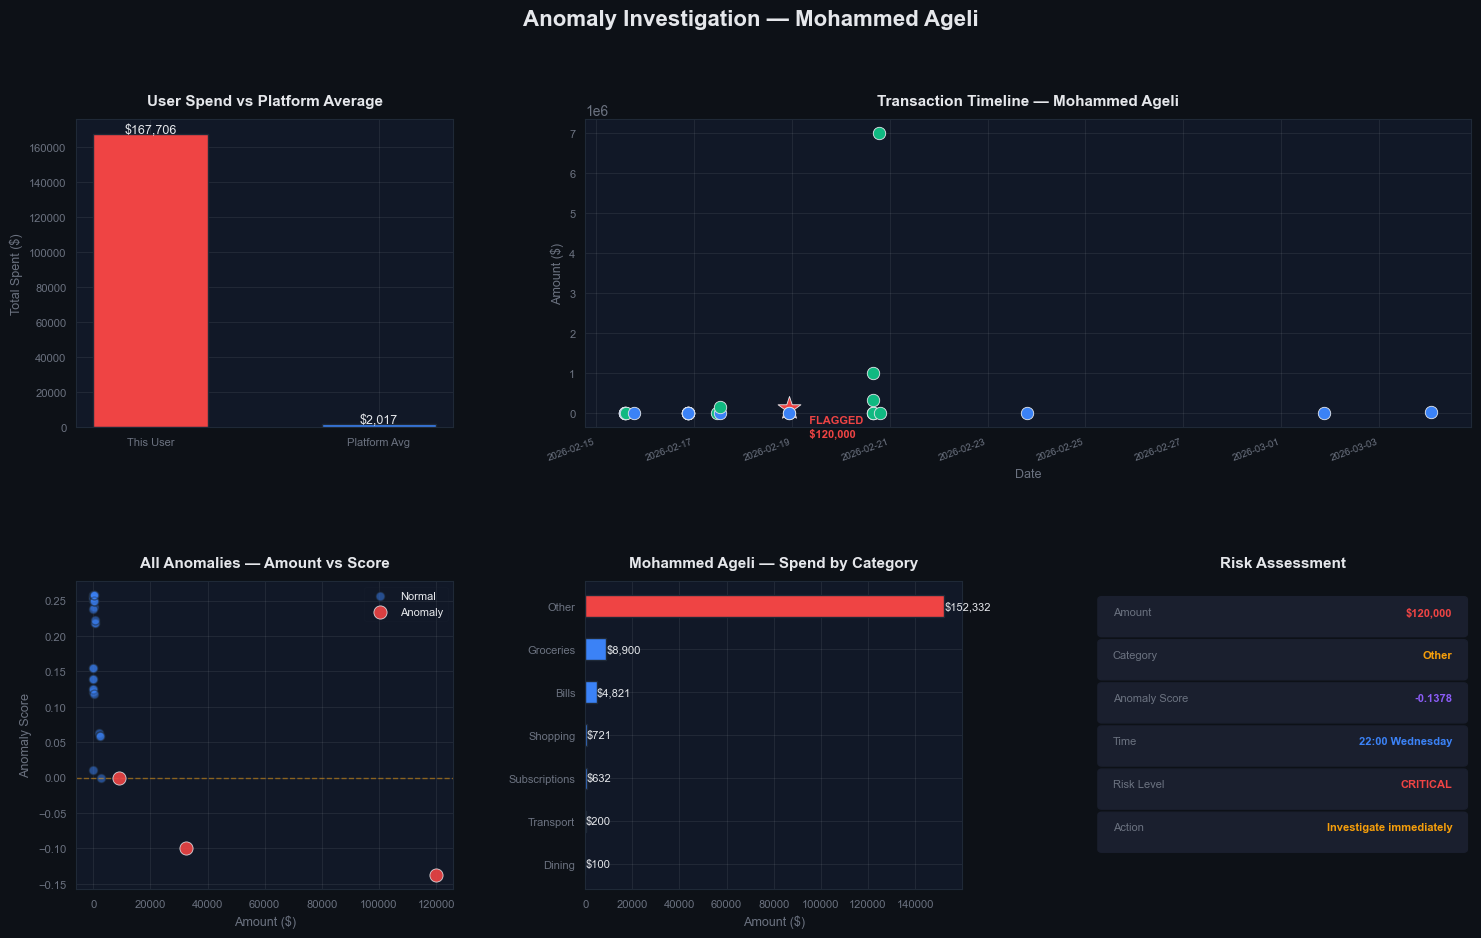

Saved: finscope_anomaly_investigation.png


In [14]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch

# ── INVESTIGATE THE $120K ANOMALY ──────────────────────────

BG, CARD, BORDER = "#0d1117", "#111827", "#1f2937"
GREEN, RED, BLUE, YELLOW, PURPLE = "#10b981", "#ef4444", "#3b82f6", "#f59e0b", "#8b5cf6"
WHITE, GREY = "#e5e7eb", "#6b7280"

df_profiles = agent_state["df_profiles"]
df_fin      = agent_state["df_fin"]

# ── Find the $120K transaction ─────────────────────────────
big = df[df["amount"] == df["amount"].max()].iloc[0]
uid = big["user_id"]

# Pull user profile
prof = df_profiles[df_profiles["id"] == uid]
name = "Unknown"
if len(prof):
    row   = prof.iloc[0]
    first = str(row.get("first_name","") or "").strip()
    last  = str(row.get("last_name","")  or "").strip()
    name  = f"{first} {last}".strip() or str(row.get("username","Unknown"))

# Pull all transactions for this user
user_txns = agent_state["df_txn"][agent_state["df_txn"]["user_id"] == uid].copy()
user_txns = user_txns.sort_values("created_at")

# Pull their finance record
user_fin  = agent_state["df_fin"][agent_state["df_fin"]["user_id"] == uid]

print("=" * 55)
print(f"  ANOMALY INVESTIGATION REPORT")
print("=" * 55)
print(f"  User       : {name}")
print(f"  User ID    : {uid}")
print(f"  Amount     : ${big['amount']:,.2f}")
print(f"  Category   : {big['category']}")
print(f"  Date       : {big['created_at'].date()}")
print(f"  Hour       : {int(big['hour']):02d}:00")
print(f"  Day        : {big['created_at'].strftime('%A')}")
print(f"  Anomaly Score: {big['anomaly_score']:.4f}")
print("=" * 55)
print(f"\n  All transactions for {name}:")
print(user_txns[["created_at","name","amount","type","category"]].to_string(index=False))
if len(user_fin):
    f = user_fin.iloc[0]
    print(f"\n  Finance summary:")
    print(f"  Balance       : ${f['balance']:,.2f}")
    print(f"  Total income  : ${f['total_income']:,.2f}")
    print(f"  Total expenses: ${f['total_expenses']:,.2f}")

# ── Ask Claude to explain it ───────────────────────────────
print("\n  Sending to Claude for analysis...")

context = {
    "user_name":       name,
    "flagged_txn": {
        "amount":        float(big["amount"]),
        "category":      big["category"],
        "date":          str(big["created_at"].date()),
        "hour":          int(big["hour"]),
        "day_of_week":   big["created_at"].strftime("%A"),
        "anomaly_score": round(float(big["anomaly_score"]), 4)
    },
    "all_user_txns":   user_txns[["name","amount","type","category"]].to_dict("records"),
    "finance":         user_fin.iloc[0][["balance","total_income","total_expenses"]].to_dict() if len(user_fin) else {}
}

investigation = claude.messages.create(
    model      = "claude-haiku-4-5-20251001",
    max_tokens = 600,
    messages   = [{
        "role": "user",
        "content": f"""You are a financial fraud analyst at FinScope AI.

Investigate this anomalous transaction and give a structured report:

{json.dumps(context, indent=2)}

Cover:
1. Why this transaction is anomalous (use the numbers)
2. Risk level: LOW / MEDIUM / HIGH / CRITICAL and why
3. Most likely explanation (legitimate or suspicious)
4. What action should be taken

Be direct and specific. No fluff."""
    }]
)

claude_analysis = investigation.content[0].text
print("\n" + "=" * 55)
print("  CLAUDE FRAUD ANALYSIS")
print("=" * 55)
print(claude_analysis)

# ── DASHBOARD ──────────────────────────────────────────────
fig = plt.figure(figsize=(18, 10))
fig.patch.set_facecolor(BG)
fig.suptitle(f"Anomaly Investigation — {name}",
             fontsize=16, fontweight="bold", color=WHITE, y=0.99)

gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.5, wspace=0.35)

def style(ax, title):
    ax.set_facecolor(CARD)
    ax.tick_params(colors=GREY, labelsize=8)
    ax.spines[:].set_color(BORDER)
    ax.grid(alpha=0.07, color="white")
    ax.set_title(title, color=WHITE, fontsize=11, fontweight="bold", pad=10)

# ── 1. This user vs all users spend ───────────────────────
ax1 = fig.add_subplot(gs[0, 0])
style(ax1, "User Spend vs Platform Average")
expenses_all  = agent_state["df_clean"]
user_total    = user_txns[user_txns["type"] == "expense"]["amount"].sum()
others_avg    = expenses_all[expenses_all["user_id"] != uid].groupby("user_id")["amount"].sum().mean()
bars = ax1.bar(["This User", "Platform Avg"],
               [user_total, others_avg],
               color=[RED, BLUE], edgecolor=BORDER, width=0.5)
for b, v in zip(bars, [user_total, others_avg]):
    ax1.text(b.get_x() + b.get_width()/2, v + 100,
             f"${v:,.0f}", ha="center", color=WHITE, fontsize=9)
ax1.set_ylabel("Total Spent ($)", color=GREY, fontsize=9)

# ── 2. Transaction timeline for this user ─────────────────
ax2 = fig.add_subplot(gs[0, 1:])
style(ax2, f"Transaction Timeline — {name}")
for _, row in user_txns.iterrows():
    color  = RED if row["amount"] == big["amount"] else (GREEN if row["type"] == "deposit" else BLUE)
    size   = 300 if row["amount"] == big["amount"] else 80
    marker = "*" if row["amount"] == big["amount"] else "o"
    ax2.scatter(row["created_at"], row["amount"],
                color=color, s=size, marker=marker,
                edgecolors=WHITE, linewidths=0.6, zorder=5)
    if row["amount"] == big["amount"]:
        ax2.annotate(f"  FLAGGED\n  ${row['amount']:,.0f}",
                     (row["created_at"], row["amount"]),
                     xytext=(10, -20), textcoords="offset points",
                     fontsize=8, color=RED, fontweight="bold")
ax2.set_ylabel("Amount ($)", color=GREY, fontsize=9)
ax2.set_xlabel("Date", color=GREY, fontsize=9)
plt.setp(ax2.get_xticklabels(), rotation=20, ha="right", fontsize=7)

# ── 3. All anomalies on scatter ───────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
style(ax3, "All Anomalies — Amount vs Score")
normal = df[~df["is_anomaly"]]
ax3.scatter(normal["amount"], normal["anomaly_score"],
            color=BLUE, alpha=0.5, s=40, label="Normal", edgecolors=BORDER)
ax3.scatter(anomalies["amount"], anomalies["anomaly_score"],
            color=RED, alpha=0.9, s=90, label="Anomaly",
            edgecolors=WHITE, linewidths=0.6, zorder=5)
ax3.axhline(0, color=YELLOW, linewidth=1, linestyle="--", alpha=0.5)
ax3.set_xlabel("Amount ($)", color=GREY, fontsize=9)
ax3.set_ylabel("Anomaly Score", color=GREY, fontsize=9)
ax3.legend(framealpha=0.15, labelcolor=WHITE, facecolor=CARD,
           edgecolor=BORDER, fontsize=8)

# ── 4. User category breakdown ────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
style(ax4, f"{name} — Spend by Category")
ucat = user_txns[user_txns["type"]=="expense"].groupby("category")["amount"].sum().sort_values()
cols = [RED if c == big["category"] else BLUE for c in ucat.index]
bars4 = ax4.barh(ucat.index, ucat.values, color=cols, edgecolor=BORDER, height=0.5)
for b, v in zip(bars4, ucat.values):
    ax4.text(v + 10, b.get_y() + b.get_height()/2,
             f"${v:,.0f}", va="center", color=WHITE, fontsize=8)
ax4.set_xlabel("Amount ($)", color=GREY, fontsize=9)

# ── 5. Risk gauge ─────────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 2])
ax5.set_facecolor(CARD)
ax5.axis("off")
ax5.set_title("Risk Assessment", color=WHITE, fontsize=11, fontweight="bold", pad=10)

risk_items = [
    ("Amount",         f"${big['amount']:,.0f}",        RED),
    ("Category",       big["category"],                  YELLOW),
    ("Anomaly Score",  f"{big['anomaly_score']:.4f}",   PURPLE),
    ("Time",           f"{int(big['hour']):02d}:00 {big['created_at'].strftime('%A')}", BLUE),
    ("Risk Level",     "CRITICAL",                       RED),
    ("Action",         "Investigate immediately",        YELLOW),
]
for i, (label, val, color) in enumerate(risk_items):
    y = 0.88 - i * 0.14
    ax5.add_patch(FancyBboxPatch((0.02, y - 0.05), 0.96, 0.11,
                                  boxstyle="round,pad=0.01",
                                  color="#1a1f2e", transform=ax5.transAxes, clip_on=False))
    ax5.text(0.05, y + 0.01, label, color=GREY,  fontsize=8,  transform=ax5.transAxes)
    ax5.text(0.95, y + 0.01, val,   color=color, fontsize=8,
             fontweight="bold", ha="right", transform=ax5.transAxes)

plt.savefig("finscope_anomaly_investigation.png", dpi=180,
            bbox_inches="tight", facecolor=BG, edgecolor="none")
plt.show()
print("Saved: finscope_anomaly_investigation.png")

